<a href="https://colab.research.google.com/github/pedrodiniz474/student-stress-svm-gridsearch/blob/main/student_stress_svm_gridsearch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Prática
###Dataset: Student Stress Factors: A Comprehensive Analysis
https://www.kaggle.com/datasets/rxnach/student-stress-factors-a-comprehensive-analysis

import kagglehub

path = kagglehub.dataset_download("rxnach/student-stress-factors-a-comprehensive-analysis")

###Objetivo: Classificar o nível de estresse de um estudante, sendo baixo ( 0 ) moderado ( 1 ) e alto (2), utilizando SVM e logo após otimizando com GridSearch. Ao final exiba a acurácia do SVM, do GridSearch e a matriz de confusão.


1. IMPORTAÇÃO DAS BIBLIOTECAS

In [ ]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

Justificativa: Importei as bibliotecas pandas pra ler tabela, sklearn pra dividir os dados, normalizar, criar o SVM e o GridSearch, e o matplotlib pra ver a matriz de confusão graficamente.

2. CARREGAMENTO E PREPARAÇÃO DOS DADOS

In [ ]:
#carregando o dataset
path = kagglehub.dataset_download("rxnach/student-stress-factors-a-comprehensive-analysis")
df = pd.read_csv(path + '/StressLevelDataset.csv')

#mostra as primeiras linhas do dataset
print(df.head())
#mostra o nome das colunas
print(df.columns)
#mostra o tipo de cada coluna
df.info()
#ve os valores nulos de cada coluna
print(df.isnull().sum())
#ve as linhas duplicadas
print(df.duplicated().sum())

#OBS: como não tem valor nulo, duplicado e as colunas sao int64 não precisou fazer um tratamento de dados nesse sentido. Portanto, continuando...

#separa a coluna 'stress_level' nossa coluna target
y = df['stress_level']

#separa o resto das colunas (as features)
X = df.drop(columns=['stress_level'])

#divide os dados, 80% para treino e 20% para teste, além de usar stratify=y pra manter a proporção das 3 classes igual no treino e no teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Using Colab cache for faster access to the 'student-stress-factors-a-comprehensive-analysis' dataset.
   anxiety_level  self_esteem  mental_health_history  depression  headache  \
0             14           20                      0          11         2   
1             15            8                      1          15         5   
2             12           18                      1          14         2   
3             16           12                      1          15         4   
4             16           28                      0           7         2   

   blood_pressure  sleep_quality  breathing_problem  noise_level  \
0               1              2                  4            2   
1               3              1                  4            3   
2               1              2                  2            2   
3               3              1                  3            4   
4               3              5                  1            3   

   living_conditions

Justitifcativa: O target é a coluna 'stress_level', e as demais colunas são as features. Usei o isnull().sum() pra ver se tem valor nulo e o duplicated().sum() pra ve se tem linha duplicada (como não tinha valor nulo nem valor duplicado não precisei tratar os dados, mas se precisasse usaria por exemplo o df.dropna()). o get_dummies também nao precisou ser feito porque as colunas ja estão em int64. Por fim, dividi 80% treino e 20% teste, com stratify para manter a proporção das 3 classes nos dois

3. TREINAMENTO COM PIPELINE E GRIDSEARCHCV

In [ ]:
#cria O Pipeline para juntar o StandardScaler e o SVM
pipe = Pipeline([('scaler', StandardScaler()), ('svm', SVC())])

#treina o modelo com os dados de treino sem ajustar parametros ainda
pipe.fit(X_train, y_train)

#define os parametros do gridsearch (3 kernel, 3 valores de C e 3 de gamma)
param_grid = {
    'svm__kernel': ['linear', 'rbf', 'sigmoid'],
    'svm__C': [0.1, 1, 10],
    'svm__gamma': [0.01, 0,1, 1]}

#configura o gridsearchcv para testar as combinações com validação cruzada
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy')

#treina o gridsearch usando os dados de treino
grid.fit(X_train, y_train)

print(grid.best_params_)

grid

{'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'linear'}


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svm', SVC())]),
             param_grid={'svm__C': [0.1, 1, 10], 'svm__gamma': [0.01, 0, 1, 1],
                         'svm__kernel': ['linear', 'rbf', 'sigmoid']},
             scoring='accuracy')

Justificativa: Usei o pipeline para juntar o StandardScaler e o SVM. O StandarScaler garante que as features não sejam priorizadas por valores muito altos ou muito baixos. Dentro do Pipeline, ele aprende só com o treino de cada fold, e isso evita vazamento de dados. O GridSearchCV testa os kernels linear, rbf e sigmoid, com 3 valores de C e 3 de gamma, usando validação cruzada com 5 folds.

4. PREVISÃO E ACURACIA

In [ ]:
print(f'Acuracia SVM: {accuracy_score(y_test, pipe.predict(X_test)) * 100:.2f} %')

#faz as previsões no teste usando o melhor modelo achado pelo GridSearch
y_pred = grid.predict(X_test)

print(f'Acurácia GridSearch: {accuracy_score(y_test, y_pred) * 100:.2f} %')

print(confusion_matrix(y_test, y_pred))


Acuracia SVM: 87.73 %
Acurácia GridSearch: 89.09 %
[[61  5  8]
 [ 2 68  2]
 [ 4  3 67]]


Justificativa: Aqui o teste é usado pela primeira vez. Comparei a acurácia do SVM com a do GridSearch e imprimi a matriz de confusão

5. VISUALIZAÇÃO DA MATRIZ DE CONFUSÃO

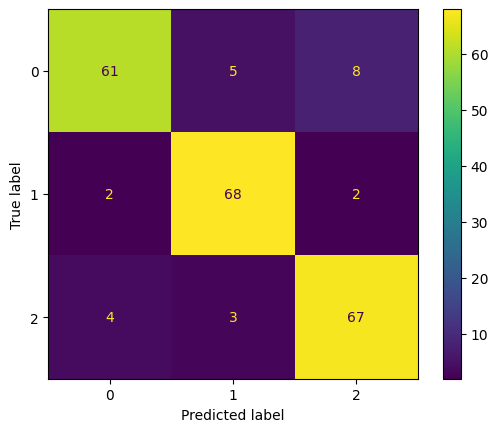

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred))

disp.plot()

plt.show()



Justificativa: A matriz mostra os acertos e os erros do modelo. As linhas são o valor real e as colunas são a previsão.